# Projeto Prático 2.1 — Perceptron de Rosenblatt

**Disciplina:** Redes Neurais Artificiais  
**Equipe:** Rennan Kauê de Oliveira Silva e Danilo Fernandes Cavalcante

Este notebook implementa o Perceptron de Rosenblatt somente com operações matriciais do NumPy. A Parte I está implementada e executável; as Partes II e III serão preenchidas após a confirmação do identificador da dupla.

## Plano de execução

1. Carregar e validar os arrays fornecidos.  
2. Implementar e executar o Perceptron até a convergência para `dataAll20262.txt` (Parte I).  
3. Executar os seis cenários, com dez repetições cada, para o arquivo definido pelo identificador da dupla (Parte II).  
4. Separar `dataHoldout20262.txt` em treino/teste, treinar por 100 épocas e avaliar as métricas (Parte III).

## Bibliotecas e funções auxiliares

In [1]:
from pathlib import Path
import math
import random

import matplotlib.pyplot as plt
import numpy as np

DADOS = Path('../rna-2026.2-pp2.1/dados')
CORES = np.array(['tab:red', 'tab:blue'])

def carregar_dados(nome_arquivo):
    """Carrega os exemplos e os normaliza para a forma (m, 3): x1, x2, yd."""
    dados = np.load(DADOS / nome_arquivo)
    dados = dados.reshape(-1, 3)
    X = dados[:, :2].astype(float)
    y = dados[:, 2].astype(int)
    if not np.all(np.isin(y, [0, 1])):
        raise ValueError('Os rótulos devem pertencer a {0, 1}.')
    return X, y

def degrau(u):
    return (u >= 0).astype(int)

def treinar_perceptron(X, y, taxa_aprendizado=0.1, intervalo=(-0.5, 0.5),
                       max_epocas=None, embaralhar=False, gerador=None, parar_na_convergencia=True):
    """Treina o Perceptron e retorna pesos, ajustes, épocas e histórico de erros."""
    if gerador is None:
        gerador = np.random.default_rng()

    X_com_bias = np.column_stack((np.ones(X.shape[0]), X))
    pesos = gerador.uniform(intervalo[0], intervalo[1], size=X_com_bias.shape[1])
    pesos_iniciais = pesos.copy()
    ajustes = 0
    historico_erros = []
    epoca = 0

    while max_epocas is None or epoca < max_epocas:
        indices = gerador.permutation(X.shape[0]) if embaralhar else np.arange(X.shape[0])
        erros = 0
        for i in indices:
            previsto = int(X_com_bias[i] @ pesos >= 0)
            erro = y[i] - previsto
            if erro != 0:
                pesos += taxa_aprendizado * erro * X_com_bias[i]
                ajustes += 1
                erros += 1
        historico_erros.append(erros)
        epoca += 1
        if erros == 0 and parar_na_convergencia:
            break

    return {
        'pesos': pesos, 'pesos_iniciais': pesos_iniciais, 'ajustes': ajustes,
        'epocas': epoca, 'historico_erros': historico_erros
    }

def prever(X, pesos):
    X_com_bias = np.column_stack((np.ones(X.shape[0]), X))
    return degrau(X_com_bias @ pesos)

def plotar_dados_e_reta(X, y, pesos, ax, titulo):
    ax.scatter(X[:, 0], X[:, 1], c=CORES[y], alpha=0.7, edgecolors='none', label=None)
    limites_x = np.array([X[:, 0].min(), X[:, 0].max()])
    if not np.isclose(pesos[2], 0):
        limites_y = -(pesos[0] + pesos[1] * limites_x) / pesos[2]
        ax.plot(limites_x, limites_y, color='black', linewidth=2, label='Reta de separação')
    else:
        ax.axvline(-pesos[0] / pesos[1], color='black', linewidth=2, label='Reta de separação')
    ax.scatter([], [], color='tab:red', label='Classe 0')
    ax.scatter([], [], color='tab:blue', label='Classe 1')
    ax.set(title=titulo, xlabel='$x_1$', ylabel='$x_2$')
    ax.legend()
    ax.grid(alpha=0.25)


## Parte I — problema linearmente separável

Configuração exigida: função degrau com limiar 0, taxa de aprendizado $\eta=0,1$ e pesos iniciais em $U(-0,5; +0,5)$. O treinamento só termina quando uma época inteira não tem erros.

Formato de X: (1000, 2)
Distribuição das classes: 0 = 500, 1 = 500
Vetor inicial de pesos [bias, w1, w2]: [-0.3338307   0.2257667   0.00485002]
Vetor final de pesos   [bias, w1, w2]: [  -0.7338307    77.26669976 -386.16459187]
Total de ajustes: 42
Épocas até a convergência: 3
Erros na última época: 0
Acurácia no conjunto de treinamento: 100.00%


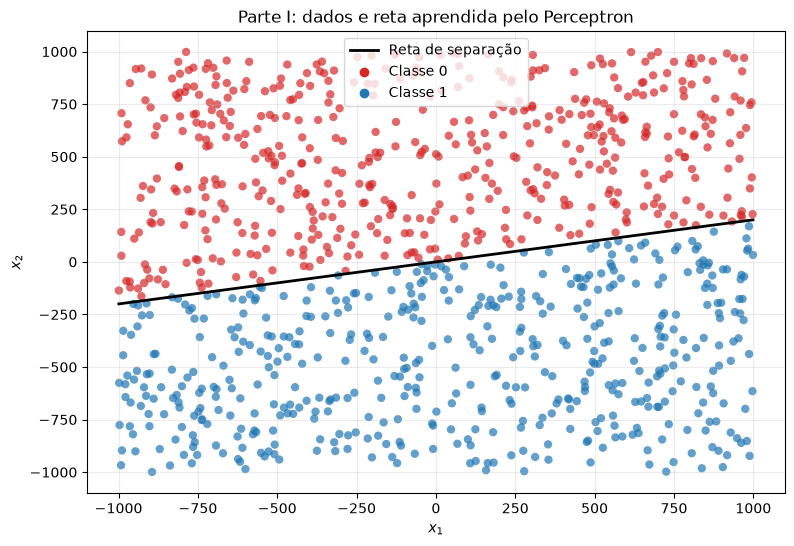

In [2]:
X_all, y_all = carregar_dados('dataAll20262.txt')
print(f'Formato de X: {X_all.shape}')
print(f'Distribuição das classes: 0 = {(y_all == 0).sum()}, 1 = {(y_all == 1).sum()}')

resultado_parte_i = treinar_perceptron(
    X_all, y_all, taxa_aprendizado=0.1, intervalo=(-0.5, 0.5)
)

print('Vetor inicial de pesos [bias, w1, w2]:', resultado_parte_i['pesos_iniciais'])
print('Vetor final de pesos   [bias, w1, w2]:', resultado_parte_i['pesos'])
print('Total de ajustes:', resultado_parte_i['ajustes'])
print('Épocas até a convergência:', resultado_parte_i['epocas'])
print('Erros na última época:', resultado_parte_i['historico_erros'][-1])
print('Acurácia no conjunto de treinamento:',
      f"{(prever(X_all, resultado_parte_i['pesos']) == y_all).mean():.2%}")

fig, ax = plt.subplots(figsize=(9, 6))
plotar_dados_e_reta(X_all, y_all, resultado_parte_i['pesos'], ax,
                     'Parte I: dados e reta aprendida pelo Perceptron')
plt.show()


## Parte II — experimentação

Como os últimos dígitos das matrículas são 6 e 6, o identificador da dupla é $(6 + 6) \bmod 4 = 0$. Portanto, esta parte usa `data020262.txt`. Cada configuração é repetida 10 vezes.

In [ ]:
from prettytable import PrettyTable

IDENTIFICADOR_EQUIPE = 0
X_exp, y_exp = carregar_dados(f'data{IDENTIFICADOR_EQUIPE}20262.txt')
configuracoes = [
    (taxa, intervalo)
    for taxa in (0.4, 0.1, 0.01)
    for intervalo in ((-100, 100), (-0.5, 0.5))
]

resumos_experimentos = []
ajustes_por_configuracao = []
for indice_configuracao, (taxa, intervalo) in enumerate(configuracoes):
    execucoes = []
    for repeticao in range(10):
        gerador = np.random.default_rng(1000 * indice_configuracao + repeticao)
        execucoes.append(treinar_perceptron(
            X_exp, y_exp, taxa_aprendizado=taxa, intervalo=intervalo, gerador=gerador
        ))
    ajustes = np.array([execucao['ajustes'] for execucao in execucoes])
    epocas = np.array([execucao['epocas'] for execucao in execucoes])
    ajustes_por_configuracao.append(ajustes)
    resumos_experimentos.append({
        'taxa': taxa, 'intervalo': intervalo, 'media_ajustes': ajustes.mean(),
        'desvio_ajustes': ajustes.std(ddof=1), 'min_epocas': epocas.min(),
        'max_epocas': epocas.max()
    })

tabela = PrettyTable()
tabela.field_names = ['Taxa de aprendizado', 'Intervalo de pesos', 'Qtde. ajustes',
                       'Min. épocas', 'Max. épocas']
for resumo in resumos_experimentos:
    tabela.add_row([
        f"η = {resumo['taxa']}", str(resumo['intervalo']),
        f"{resumo['media_ajustes']:.2f} ± {resumo['desvio_ajustes']:.2f}",
        resumo['min_epocas'], resumo['max_epocas']
    ])
print(tabela)


In [ ]:
rotulos = [f"η={taxa}\nU{intervalo}" for taxa, intervalo in configuracoes]
fig, ax = plt.subplots(figsize=(12, 6))
ax.boxplot(ajustes_por_configuracao, tick_labels=rotulos, showmeans=True)
ax.set(title='Parte II: distribuição dos ajustes em 10 repetições',
       xlabel='Configuração', ylabel='Quantidade de ajustes')
ax.grid(axis='y', alpha=0.25)
plt.show()

melhor = min(resumos_experimentos, key=lambda resumo: resumo['media_ajustes'])
pior = max(resumos_experimentos, key=lambda resumo: resumo['media_ajustes'])
print('Pela média de ajustes, a configuração mais eficiente foi '
      f"η={melhor['taxa']}, U{melhor['intervalo']}; a menos eficiente foi "
      f"η={pior['taxa']}, U{pior['intervalo']}. Como todas convergiram, a comparação "
      'é de eficiência de treinamento, não de acurácia final.')


## Parte III — validação holdout em problema não linearmente separável

O conjunto é inicialmente visualizado para evidenciar a ausência de uma única reta separadora. Depois, ele é dividido aleatoriamente em 70% para treinamento e 30% para teste, com semente 0. O treinamento usa $\eta=0,1$, pesos em $U(-0,5; +0,5)$ e exatamente 100 épocas, embaralhando os exemplos a cada época.

In [ ]:
X_holdout, y_holdout = carregar_dados('dataHoldout20262.txt')
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X_holdout[:, 0], X_holdout[:, 1], c=CORES[y_holdout], alpha=0.7, edgecolors='none')
ax.scatter([], [], color='tab:red', label='Classe 0')
ax.scatter([], [], color='tab:blue', label='Classe 1')
ax.set(title='Problema holdout: classes não linearmente separáveis', xlabel='$x_1$', ylabel='$x_2$')
ax.legend()
ax.grid(alpha=0.25)
plt.show()

gerador_holdout = np.random.default_rng(IDENTIFICADOR_EQUIPE)
indices = gerador_holdout.permutation(X_holdout.shape[0])
limite_treino = int(0.7 * X_holdout.shape[0])
indices_treino, indices_teste = indices[:limite_treino], indices[limite_treino:]
X_treino, y_treino = X_holdout[indices_treino], y_holdout[indices_treino]
X_teste, y_teste = X_holdout[indices_teste], y_holdout[indices_teste]
print(f'Treino: {X_treino.shape[0]} exemplos | Teste: {X_teste.shape[0]} exemplos')


In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score

resultado_holdout = treinar_perceptron(
    X_treino, y_treino, taxa_aprendizado=0.1, intervalo=(-0.5, 0.5),
    max_epocas=100, embaralhar=True, gerador=gerador_holdout, parar_na_convergencia=False
)
y_previsto_teste = prever(X_teste, resultado_holdout['pesos'])
matriz_confusao = confusion_matrix(y_teste, y_previsto_teste, labels=[0, 1])
acuracia = accuracy_score(y_teste, y_previsto_teste)
precisao = precision_score(y_teste, y_previsto_teste, zero_division=0)
revocacao = recall_score(y_teste, y_previsto_teste, zero_division=0)
fscore = f1_score(y_teste, y_previsto_teste, zero_division=0)

print('Matriz de confusão (linhas: real; colunas: previsto):')
print(matriz_confusao)
print(f'Acurácia:  {acuracia:.2%}')
print(f'Precisão:  {precisao:.2%}')
print(f'Revocação: {revocacao:.2%}')
print(f'F1-Score:  {fscore:.2%}')
print(f'Ajustes em 100 épocas: {resultado_holdout["ajustes"]}')


In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
plotar_dados_e_reta(X_treino, y_treino, resultado_holdout['pesos'], eixos[0],
                     'Solução sobre o conjunto de treinamento')
plotar_dados_e_reta(X_teste, y_teste, resultado_holdout['pesos'], eixos[1],
                     'Solução sobre o conjunto de teste')
plt.tight_layout()
plt.show()

print('Discussão: como o conjunto não é linearmente separável, uma reta não consegue '
      'classificar todos os padrões corretamente. A qualidade da solução deve ser julgada '
      'principalmente pela acurácia, precisão, revocação e F1-Score obtidos acima; valores '
      'menores indicam sobreposição relevante das classes para este modelo linear.')
